Overview of the Dataset
       variance  skewness  curtosis  entropy  class
0      3.62160   8.66610   -2.8073 -0.44699      0
1      4.54590   8.16740   -2.4586 -1.46210      0
2      3.86600  -2.63830    1.9242  0.10645      0
3      3.45660   9.52280   -4.0112 -3.59440      0
4      0.32924  -4.45520    4.5718 -0.98880      0
...        ...       ...       ...      ...    ...
1367   0.40614   1.34920   -1.4501 -0.55949      1
1368  -1.38870  -4.87730    6.4774  0.34179      1
1369  -3.75030 -13.45860   17.5932 -2.77710      1
1370  -3.56370  -8.38270   12.3930 -1.28230      1
1371  -2.54190  -0.65804    2.6842  1.19520      1

[1372 rows x 5 columns]
       μ(variance)  σ(variance)  μ(skewness)  σ(skewness)  μ(curtosis)  \
class                                                                    
0             2.28         2.02         4.26         5.14         0.80   
1            -1.87         1.88        -0.99         5.40         2.15   
all           0.43         2.84         1.

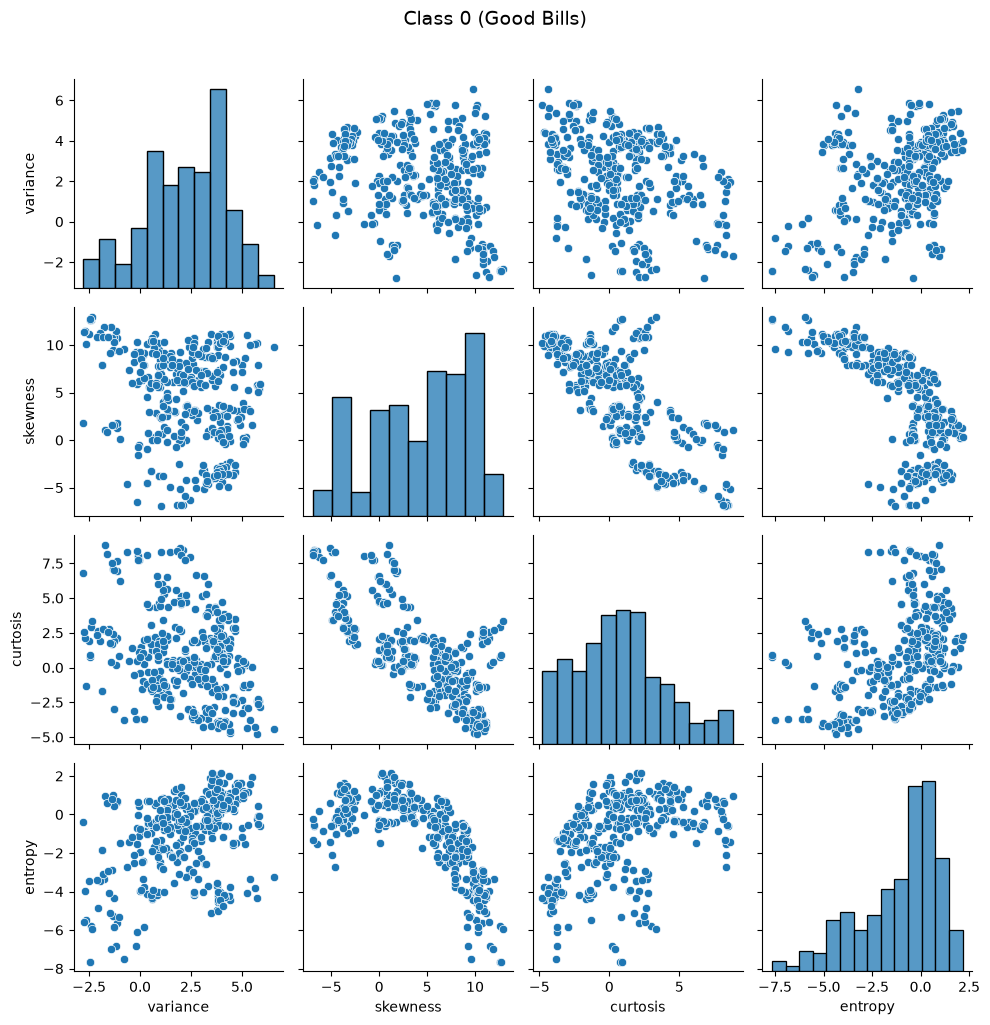

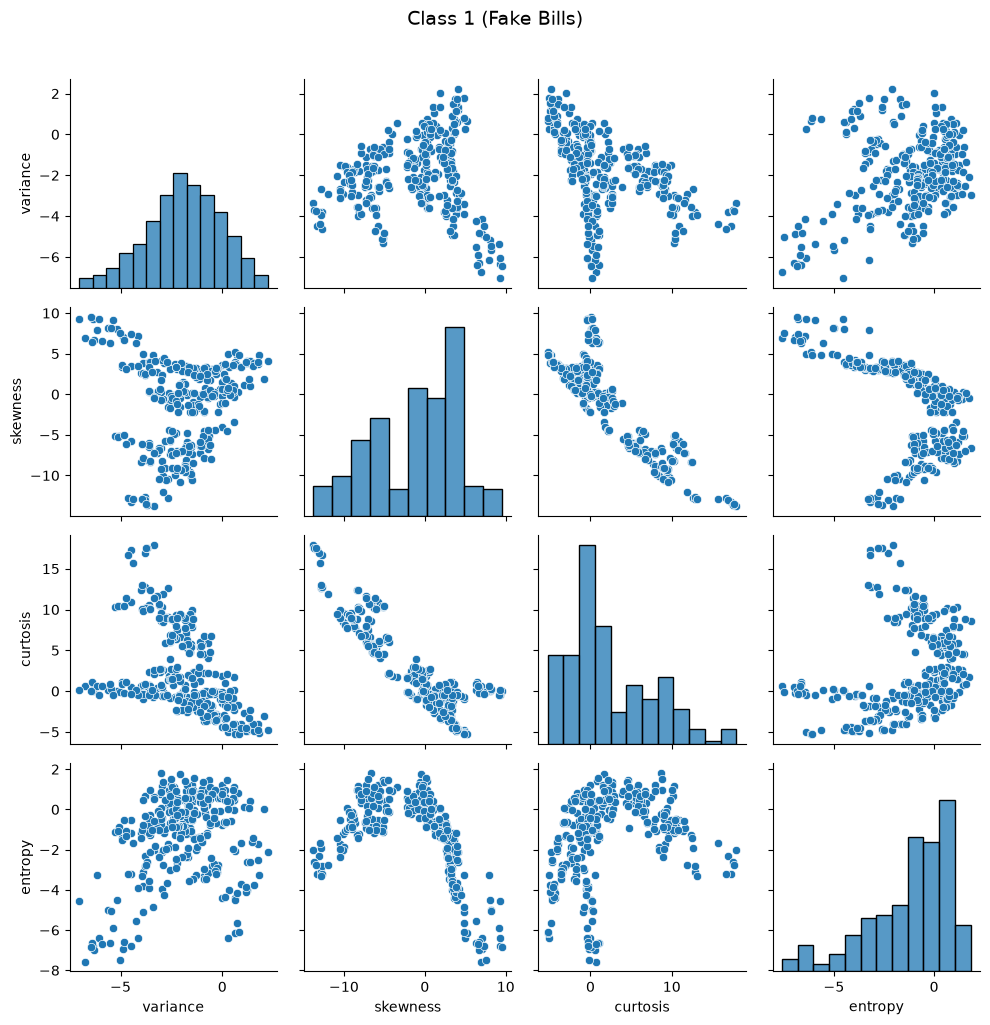

Confusion Matrix: Simple Classifier
           TP    FP     TN     FN  accuracy    TPR     TNR
Value  171.0  10.0  290.0  215.0     0.672  0.443  0.9667

Conclusion:
The simple classifier has higher accuracy in identifying real bills.
The overall accuracy is at 0.672, which is better than coin flipping
k           Accuracy
3             1.0000
5             1.0000
7             1.0000
9             0.9956
11            0.9913

Optimal k: [3, 5, 7] 
Accuracy: 1.0000


/var/folders/f9/tdjvw_7s3p16fd0k5csv6xk40000gn/T/ipykernel_84496/483284947.py:130: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_train.drop(columns=['class'], inplace=True)
/var/folders/f9/tdjvw_7s3p16fd0k5csv6xk40000gn/T/ipykernel_84496/483284947.py:131: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_test.drop(columns=['class'], inplace=True)


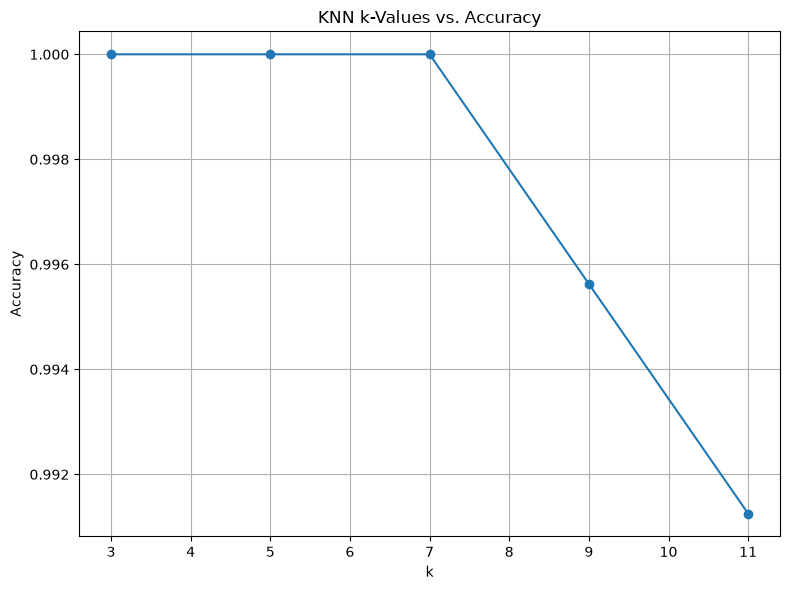


Confusion Matrix: KNN (k=3)
           TP   FP     TN   FN  accuracy  TPR  TNR
Value  386.0  0.0  300.0  0.0       1.0  1.0  1.0

Conclusion:
The KNN model achieved 100% accuracy, and outperforms the simple classifier in every metric.

For a banknote with feature values of my BUID last 4 digits(0953):
The simple classifier model predicts it as fake.
The KNN model predicts it as real.
Accuracies with Truncated Data: KNN
Dropped Feature       Accuracy
variance                0.9563 
skewness                0.9781 
curtosis                0.9679 
entropy                 0.9956 

Observations:
The accuracy decreased when any of the four feature dropped.
Variance contributes the most to accuracy loss, where accuracy dropped to 0.9606.
Entropy contributes the least to accuracy loss, where the accuracy dropped to 0.9898

Confusion Matrix: Logistic Regression
           TP     FP     TN   FN  accuracy  TPR     TNR
Value  386.0  109.0  191.0  0.0    0.8411  1.0  0.6367

Conclusion:
The logisti

In [ ]:
import sys
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# ANSI escape code for output formatting
BOLD = "\033[1m" if "idlelib" not in sys.modules else ""
RESET = "\033[0m" if "idlelib" not in sys.modules else ""

# load the banknote dataset
col_names = ['variance', 'skewness', 'curtosis', 'entropy', 'class']  # class 0: real, class 1: fake

df = pd.read_csv('data_banknote_authentication.txt', header=None, names=col_names)
print(f'{BOLD}Overview of the Dataset\n{RESET}', df)


"""
Add colour label for each banknote, analyze the feature data stats
"""
# add label column
df['label'] = df['class'].apply(lambda x: '+' if x == 0 else '-')

# feature mean and std
features = ['variance', 'skewness', 'curtosis', 'entropy']

summary = (df.groupby('class')[features].agg(['mean', 'std']))
summary.loc['all'] = df[features].agg(['mean', 'std']).T.values.flatten()
summary.columns = [f"{'μ' if stat == 'mean' else 'σ'}({f})" for f, stat in summary.columns]

pd.set_option('display.max_columns', None)
print(summary.round(2))

print(f'\n{BOLD}Observations:{RESET}'
      '\nVariance: Class 0 tends to have much higher wavelet distribution mean variance than the overall '
      '\ndataset, while Class 1 has negative mean variance with smaller magnitude.  The standard deviation '
      '\nof wavelet variance for the two classes are fairly comparable. These suggest that the wavelet '
      '\ndistributions in Class 0 images are more spread out; however, the levels of wavelet variance'
      '\nvariability are similar across the two classes.'

      '\n\nSkewness: Class 0 exhibits a higher mean wavelet skewness, whereas Class 1 has negative '
      '\nvalues, denoting that the wavelet distributions are highly right-skewed in Class 0 images, and '
      '\nslightly left-skewed in Class 1 images.'

      '\n\nCurtosis: Class 0 has a relatively low mean curtosis compare to Class 1, meanwhile the '
      '\ncurtosis standard deviations is significant higher in Class 1 than Class 0. These indicate '
      '\nthat the wavelet distributions in Class 1 images have higher variations with longer tails compared'
      '\nto Class 0 images.'

      '\n\nEntropy: Both mean and standard deviation of entropy are quite close within the two classes,'
      '\nsuggesting that wavelet distributions in both class images are fairly structured with minimum '
      '\nrandomness.')


"""
Employ a simple classifier through visually examine the distribution of features on pairplots
to predict the banknote legitimacy.
"""
# split dataset
X_train, X_test = train_test_split(df, test_size=0.5, random_state=42)

class_0 = X_train[X_train['class'] == 0]
class_1 = X_train[X_train['class'] == 1]


with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="use_inf_as_na option is deprecated")

    g = sns.pairplot(class_0.drop(columns='class'))
    g.fig.suptitle("Class 0 (Good Bills)", y=1.02, fontsize=14)
    g.fig.tight_layout()
    plt.show()

    g = sns.pairplot(class_1.drop(columns='class'))
    g.fig.suptitle("Class 1 (Fake Bills)", y=1.02, fontsize=14)
    g.fig.tight_layout()
    plt.show()


def simple_classifier(variance, skewness, curtosis):
    """
    By visually examine the pairplots, the thresholds for each feature are set based on the dense
    clusters of the good bills.
    The entropy feature is discarded due to similar distribution among both classes
    """
    if (variance > 1) and (skewness > 2) and (curtosis < 8):
        return '+'  # good bill
    else:
        return '-'  # bad bill


spl_clf_pred = X_test.copy()
spl_clf_pred['pred_label'] = X_test.apply(lambda row: simple_classifier(row.iloc[0], row.iloc[1], row.iloc[2]), axis=1)


def cm(df):
    # confusion matrix
    TP = ((df['pred_label'] == '+') & (df['label'] == '+')).sum()
    FP = ((df['pred_label'] == '+') & (df['label'] == '-')).sum()
    TN = ((df['pred_label'] == '-') & (df['label'] == '-')).sum()
    FN = ((df['pred_label'] == '-') & (df['label'] == '+')).sum()

    accuracy = (TP + TN) / (TP + FP + TN + FN)
    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    TNR = TN / (TN + FP) if (TN + FP) > 0 else 0

    cm_table = pd.DataFrame({
        'Value': [TP, FP, TN, FN, accuracy, TPR, TNR]},
        index=['TP', 'FP', 'TN', 'FN', 'accuracy', 'TPR', 'TNR'])

    return cm_table.round(4).T


spl_clf_cm = cm(spl_clf_pred)
print(f'{BOLD}Confusion Matrix: Simple Classifier{RESET}\n',spl_clf_cm)

print(f'\n{BOLD}Conclusion:{RESET}'
      '\nThe simple classifier has higher accuracy in identifying real bills.'
      '\nThe overall accuracy is at 0.672, which is better than coin flipping')


"""
Use KNN to predict the banknote legitimacy
"""
X_train.drop(columns=['class'], inplace=True)
X_test.drop(columns=['class'], inplace=True)


def knn(k, X_train, X_test):
    knn_model = KNeighborsClassifier(n_neighbors=k)

    X = X_train.drop(columns='label')
    y = X_train['label']

    knn_model.fit(X,y)
    y_pred = knn_model.predict(X_test.drop(columns = 'label'))
    acc = accuracy_score(X_test['label'], y_pred)

    pred_df = X_test.copy()
    pred_df['pred_label'] = y_pred

    return knn_model, pred_df, acc


# find optimal k value
k_values = [3, 5, 7, 9, 11]
knn_accuracies = []

print(f"{'k':<10}{'Accuracy':>10}")
for k in k_values:
    _, _, acc = knn(k, X_train, X_test)
    knn_accuracies.append(acc)
    print(f'{k:<10}{acc:>10.4f}')

best_k = [k for k, acc in zip(k_values, knn_accuracies) if acc == max(knn_accuracies)]
best_k_acc = max(knn_accuracies)
print(f'\nOptimal k: {best_k} '
      f'\nAccuracy: {best_k_acc:.4f}')

# plot accuracy graph
plt.figure(figsize=(8, 6))
plt.plot(k_values, knn_accuracies, marker='o')
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("KNN k-Values vs. Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()
plt.close()

# compute confusion matrix for knn w/ best k
_, knn_pred, _ = knn(best_k[-1], X_train, X_test)

knn_cm = cm(knn_pred)
print(f'\n{BOLD}Confusion Matrix: KNN (k=3){RESET}\n', knn_cm)

print(f'\n{BOLD}Conclusion:{RESET}'
      '\nThe KNN model achieved 100% accuracy, and outperforms the simple classifier in every metric.')


# use last 4 digits of BUID as feature values to evaluate the banknote
new_instance = pd.DataFrame([[0, 9, 5, 3]], columns=['variance', 'skewness', 'curtosis', 'entropy'])

bu_bill_spl_clf = simple_classifier(new_instance.iloc[0, 0], new_instance.iloc[0, 1], new_instance.iloc[0, 2])
knn_model, _, _ = knn(best_k[-1], X_train, X_test)
bu_bill_knn = knn_model.predict(new_instance)

print(f'\n{BOLD}For a banknote with feature values of my BUID last 4 digits(0953):{RESET}')
for model, sign in zip(['simple classifier', 'KNN'], [bu_bill_spl_clf, bu_bill_knn]):
    result = 'real' if sign == '+' else 'fake'
    print(f'The {model} model predicts it as {result}.')


"""
Evaluate the change in accuracy for knn model with each feature dropped from the dataset
"""
# knn accuracies with dropped features
knn_trunc_accuracies = []
print(f'{BOLD}Accuracies with Truncated Data: KNN{RESET}'
      f"\n{'Dropped Feature':<15}{'Accuracy':>15}")

for col in features:  # used the largest optimal k for better generalization and stability
    _, _, acc = knn(best_k[-1], X_train.drop(columns=col), X_test.drop(columns=col))
    knn_trunc_accuracies.append(acc)
    print(f'{col:<15}{acc:>15.4f} ')

print(f'\n{BOLD}Observations:{RESET}'
      '\nThe accuracy decreased when any of the four feature dropped.'
      '\nVariance contributes the most to accuracy loss, where accuracy dropped to 0.9606.'
      '\nEntropy contributes the least to accuracy loss, where the accuracy dropped to 0.9898')


"""
Use logistic regression to predict the banknote legitimacy
"""
def log_reg(X_train, X_test):
    scaler = StandardScaler()
    log_clf = LogisticRegression()

    X = X_train.drop(columns='label')
    y = X_train['label']
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

    log_clf.fit(X_scaled, y)

    y_pred = log_clf.predict(X_test.drop(columns='label'))
    acc = accuracy_score(X_test['label'], y_pred)

    pred_df = X_test.copy()
    pred_df['pred_label'] = y_pred

    return log_clf, pred_df, acc


# confusion matrix for logistic regression
log_clf, log_pred, log_acc = log_reg(X_train, X_test)
log_reg_cm = cm(log_pred)
print(f'\n{BOLD}Confusion Matrix: Logistic Regression{RESET}\n', log_reg_cm)

print(f'\n{BOLD}Conclusion:{RESET}'
      '\nThe logistics Regression model outperforms the simple classifiers in terms of accuracy and TPR, '
      '\nbut falls behind on TNR.'
      '\nThe logistic regression does not outperforms the KNN model on any measures.')

# predict for the banknote with BUID feature values
bu_bill_log = log_clf.predict(new_instance)
result_bu_log = 'real' if bu_bill_log == '+' else 'fake'
compare_log_knn = 'same as' if bu_bill_log == bu_bill_knn else 'different from'

print(f'\n{BOLD}For a banknote with feature values of my BUID last 4 digits(0953):{RESET}'
      f'\nThe logistic regression model predicts it as {result_bu_log}, {compare_log_knn} the knn model result.')


"""
Evaluate the change in accuracy for logistic regression model with each feature dropped from the dataset
            Compare the feature relative significance in knn and logistic regression model
"""
# logistic regression accuracies with dropped features
log_trunc_accuracies = []
print(f'{BOLD}Accuracies with Truncated Dara: Logistic Regression{RESET}'
      f"\n{'Dropped Feature':<15}{'Accuracy':>15}")

for col in features:
    _, _, acc = log_reg(X_train.drop(columns=col), X_test.drop(columns=col))
    log_trunc_accuracies.append(acc)
    print(f'{col:<15}{acc:>15.4f} ')

print(f'\n{BOLD}Observations:{RESET}'
      '\nThe accuracy decreased when any of the four feature dropped.'
      '\nVariance contributes the most to accuracy loss, where accuracy dropped to 0.6560.'
      '\nEntropy contributes the least to accuracy loss, where the accuracy dropped to 0.8382')


# relative significance of features for knn and logistic regression
knn_rel_sig = [(best_k_acc - acc) / best_k_acc for acc in knn_trunc_accuracies]
log_rel_sig = [(log_acc - acc) / log_acc for acc in log_trunc_accuracies]

feature_rel_sig = pd.DataFrame({
    'Feature': features,
    'KNN': knn_rel_sig,
    'Logistic Regression': log_rel_sig
})

print(f'\n{BOLD}Feature Relative Significance{RESET}\n',
    feature_rel_sig.round(4))

print(f'\n{BOLD}Conclusion:{RESET}'
      f'\nThe ranking of feature significance remains consistent across both knn and logistic regress models.  '
      f"\nHowever, the magnitude of the features' impact on accuracy notably, i.e the logistic regression model"
      f'\nexperiences a sharp 0.2291 decline in accuracy when variance is removed from the dataframe, compared '
      f'\nto the 0.0394 drop in knn.  This suggest that the logistic regression model may rely more heavily on '
      f'\nindividual informative features, while the knn model was able to better compensate through the remaining '
      f'\nfeatures due to its distance-based nature.')